# Autoencoders: Learning a Compact "Fingerprint" of Mars Terrain


Planetary missions return far more images than anyone can label. An **autoencoder** is a neural network that learns from images **without any labels**. Its only task is:

> squeeze an image down to a handful of numbers, then rebuild the image from those numbers alone.

To succeed, the network must discover what matters most in the images. The handful of numbers in the middle is called the **latent space** (or *code*, or *embedding*). It works like a compact fingerprint of each image. Similar-looking terrain gets similar fingerprints, which lets us **search**, **group**, and **map** terrain with no labels at all.

### Learning goals
1. Explain the encoder → bottleneck → decoder idea, and why the bottleneck forces the network to learn.
2. Train an autoencoder in PyTorch and judge its reconstructions.
3. Interpret the **latent space**: what the 16 numbers capture, and how moving through the space changes the image.
4. Use the latent space for **similarity search** and **unsupervised clustering**, and turn the clusters into a terrain map.






---
## Step 0: Setup

In [1]:
import os

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import skimage.io
from skimage.color import rgb2gray
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.neighbors import NearestNeighbors

import torch
from torch import nn

device = torch.device('cuda' if torch.cuda.is_available()
                      else 'mps' if torch.backends.mps.is_available() else 'cpu')
print(f'PyTorch {torch.__version__} | running on: {device}')

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
plt.rcParams.update({'figure.dpi': 100, 'axes.titlesize': 11})

PyTorch 2.15.0 | running on: mps


In [2]:
# ======================= SETTINGS (the knobs) =======================
DATA_DIR   = 'data/tiled_img_brain_terrain_64'
LATENT_DIM = 16       # size of the bottleneck: how many numbers describe each tile
EPOCHS     = 80       # passes through the training tiles
BATCH_SIZE = 32
LR         = 2e-3     # peak learning rate
ROUGHNESS_WEIGHT = 10 # how much the loss cares about texture (Step 3); 0 = plain pixel loss
N_CLUSTERS = 4        # number of terrain groups to look for in Step 7
# ====================================================================

---
## Step 1: The data, Martian "brain terrain"

Our data is one orbital image of the Martian surface, cut into a grid of **28 × 30 = 840 tiles** of 64 × 64 pixels. The file name `brain_sublime_ice_tile_<row>_<col>.png` tells us where each tile sits in the grid.

**Brain terrain** is a pattern of closed-cell ridges and troughs that looks like the folds of a brain. It is common on **ice-rich deposits in the Martian mid-latitudes** (lobate debris aprons, lineated valley fill, concentric crater fill) and is thought to form as buried **ice sublimates** (turns directly from solid to gas).

We have **no labels** for these tiles, which is exactly the situation autoencoders are made for.

In [3]:
ROWS, COLS, T = 28, 30, 64

tiles, grid_pos = [], []
for r in range(ROWS):
    for c in range(COLS):
        img = skimage.io.imread(f'{DATA_DIR}/brain_sublime_ice_tile_{r}_{c}.png')
        tiles.append(rgb2gray(img))          # color -> grayscale, values 0..1
        grid_pos.append((r, c))
tiles = np.array(tiles, dtype=np.float32)    # (840, 64, 64)
grid_pos = np.array(grid_pos)                # (840, 2): row, col of every tile
tile_index = {tuple(rc): i for i, rc in enumerate(grid_pos)}
rc_text = lambda i: f'({grid_pos[i][0]}, {grid_pos[i][1]})'   # "(row, col)" label of tile i

def assemble(tile_stack):
    # Put 840 tiles back together into the full (28*64) x (30*64) scene
    return tile_stack.reshape(ROWS, COLS, T, T).transpose(0, 2, 1, 3).reshape(ROWS * T, COLS * T)

mosaic = assemble(tiles)
print('tiles:', tiles.shape, '| value range:', tiles.min(), 'to', tiles.max())
print('full scene:', mosaic.shape, 'pixels')
print(f'each tile = {T} x {T} = {T * T:,} numbers')

tiles: (840, 64, 64) | value range: 0.0 to 1.0
full scene: (1792, 1920) pixels
each tile = 64 x 64 = 4,096 numbers


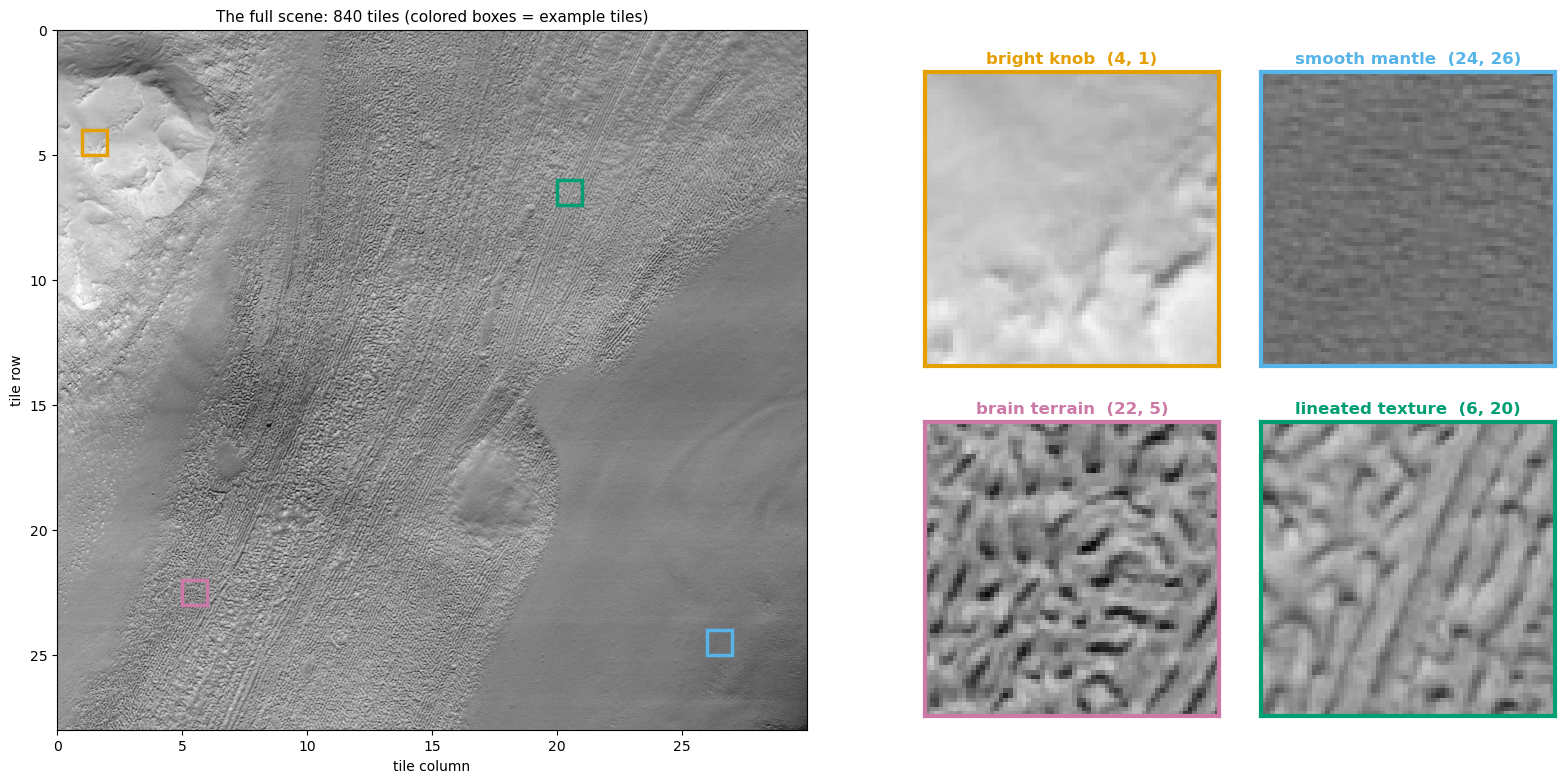

In [4]:
# A few named example tiles that we will follow through the whole notebook
EXAMPLES = {'bright knob': (4, 1), 'smooth mantle': (24, 26),
            'brain terrain': (22, 5), 'lineated texture': (6, 20)}
EX_COLORS = ['#E69F00', '#56B4E9', '#CC79A7', '#009E73']

def mark_tile(ax, rc, color, lw=2.5, label=None):
    r, c = rc
    ax.add_patch(plt.Rectangle((c * T, r * T), T, T, fill=False, ec=color, lw=lw, label=label))

fig = plt.figure(figsize=(16, 7))
ax = fig.add_axes([0.0, 0.0, 0.55, 1.0])
ax.imshow(mosaic, cmap='gray')
for (name, rc), col in zip(EXAMPLES.items(), EX_COLORS):
    mark_tile(ax, rc, col, label=name)
ax.set_title('The full scene: 840 tiles (colored boxes = example tiles)')
ax.set_xticks(np.arange(0, COLS * T, 5 * T), np.arange(0, COLS, 5)); ax.set_xlabel('tile column')
ax.set_yticks(np.arange(0, ROWS * T, 5 * T), np.arange(0, ROWS, 5)); ax.set_ylabel('tile row')
for k, ((name, rc), col) in enumerate(zip(EXAMPLES.items(), EX_COLORS)):
    a = fig.add_axes([0.58 + 0.21 * (k % 2), 0.52 - 0.5 * (k // 2), 0.19, 0.42])
    a.imshow(tiles[tile_index[rc]], cmap='gray', vmin=0, vmax=1)
    a.set_title(f'{name}  {rc}', color=col, fontsize=12, weight='bold'); a.set_xticks([]); a.set_yticks([])
    for s in a.spines.values(): s.set_color(col); s.set_linewidth(3)
plt.show()

### Split into training and test tiles
The network learns from 700 training tiles. The other 140 are held back to check that it works on tiles it has never seen.

In [5]:
perm = np.random.default_rng(SEED).permutation(len(tiles))
train_idx, test_idx = perm[:700], perm[700:]

# PyTorch wants (number, channels, height, width); grayscale -> 1 channel
X_all = torch.tensor(tiles).unsqueeze(1)
X_train, X_test = X_all[train_idx], X_all[test_idx]
print('train:', tuple(X_train.shape), ' test:', tuple(X_test.shape))

train: (700, 1, 64, 64)  test: (140, 1, 64, 64)


---
## Step 2: Build the autoencoder

<center><img src="../files/ae_architecture.png" alt="Autoencoder architecture" width="900"></center>

* **Encoder (blue).** Three rounds of *convolution → max-pool*. Each round halves the tile size and detects more complex patterns: edges, then ridges, then textures. A final **fully connected (linear) layer** compresses everything into **16 numbers**.
* **Bottleneck (red): the latent vector.** 4,096 pixel values become just 16 numbers, a 256× compression. *This is the only information the decoder gets.*
* **Decoder (green).** The mirror image: a linear layer expands the 16 numbers, then *upsampling + convolution* steps rebuild a 64 × 64 tile.
* **Training goal:** make the output as close as possible to the input (details of "close" in Step 3).

Why does this teach the network anything? If the bottleneck were as big as the image, the network could just copy pixels. Because it is tiny, the network is forced to keep **only the most important, most common patterns** in the data.

> **Note: no skip connections here.** In the segmentation notebook you will meet the **U-Net**, which looks like this hourglass plus *skip connections* that pass detailed feature maps straight from encoder to decoder. That is great for drawing sharp maps, but in an autoencoder it would let the decoder **bypass the bottleneck** and the 16 numbers would learn little. To study the latent space, we keep it plain.

The building blocks, as a reminder:

| Convolution | Max pooling | Transposed convolution (upsampling) |
|---|---|---|
| <img src="../files/conv_operation.png" width="280"> | <img src="../files/pooling_layer.png" width="280"> | <img src="../files/trans_conv.png" width="280"> |

In [6]:
def down_block(in_ch, out_ch):
    # convolution -> batch norm -> ReLU -> max-pool (halves height and width)
    return nn.Sequential(nn.Conv2d(in_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(),
                         nn.MaxPool2d(2))

def up_block(in_ch, out_ch):
    # transposed convolution (doubles height and width) -> convolution
    return nn.Sequential(nn.ConvTranspose2d(in_ch, out_ch, 2, stride=2), nn.BatchNorm2d(out_ch), nn.ReLU(),
                         nn.Conv2d(out_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU())

class Autoencoder(nn.Module):
    def __init__(self, latent_dim=16):
        super().__init__()
        self.encoder = nn.Sequential(
            down_block(1, 32),               # 1 x 64 x 64  -> 32 x 32 x 32
            down_block(32, 64),              #              -> 64 x 16 x 16
            down_block(64, 128),             #              -> 128 x 8 x 8
            nn.Flatten(),                    #              -> 8,192 numbers
            nn.Linear(128 * 8 * 8, latent_dim),   #         -> 16 numbers (the latent vector)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128 * 8 * 8), nn.ReLU(),   # 16 numbers -> 8,192
            nn.Unflatten(1, (128, 8, 8)),    #              -> 128 x 8 x 8
            up_block(128, 64),               #              -> 64 x 16 x 16
            up_block(64, 32),                #              -> 32 x 32 x 32
            up_block(32, 16),                #              -> 16 x 64 x 64
            nn.Conv2d(16, 1, 3, padding=1), nn.Sigmoid(),    # -> 1 x 64 x 64, values 0..1
        )

    def encode(self, x):
        return self.encoder(x)

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        return self.decode(self.encode(x))

model = Autoencoder(LATENT_DIM).to(device)
print(f'Trainable parameters: {sum(p.numel() for p in model.parameters()):,}')

Trainable parameters: 455,681


Follow one tile through the network and watch the shape shrink to 16 numbers and grow back:

In [7]:
x = X_test[:1].to(device)
print(f'{"stage":<34}{"shape"}')
print('-' * 55)
print(f'{"input tile":<34}{tuple(x.shape)}')
with torch.no_grad():
    for layer in model.encoder:
        x = layer(x)
        print(f'{"encoder  " + layer.__class__.__name__:<34}{tuple(x.shape)}')
    print(f'{"    >>> LATENT VECTOR <<<":<34}{tuple(x.shape)}')
    for layer in model.decoder:
        x = layer(x)
        if not isinstance(layer, nn.ReLU):
            print(f'{"decoder  " + layer.__class__.__name__:<34}{tuple(x.shape)}')

stage                             shape
-------------------------------------------------------
input tile                        (1, 1, 64, 64)
encoder  Sequential               (1, 32, 32, 32)
encoder  Sequential               (1, 64, 16, 16)
encoder  Sequential               (1, 128, 8, 8)
encoder  Flatten                  (1, 8192)
encoder  Linear                   (1, 16)
    >>> LATENT VECTOR <<<         (1, 16)
decoder  Linear                   (1, 8192)
decoder  Unflatten                (1, 128, 8, 8)
decoder  Sequential               (1, 64, 16, 16)
decoder  Sequential               (1, 32, 32, 32)
decoder  Sequential               (1, 16, 64, 64)
decoder  Conv2d                   (1, 1, 64, 64)
decoder  Sigmoid                  (1, 1, 64, 64)


---
## Step 3: Train

The training loop is the same four steps as in Notebook 1, except that **the target is the input itself**:
1. forward pass: encode and decode a batch of tiles
2. loss: how different is the output from the input?
3. backpropagation: compute the gradients
4. update: nudge the weights to reduce the loss

### The loss: pixels + roughness
The usual autoencoder loss is the **pixel error** (mean squared difference between output and input pixels). On its own, it has a weakness for terrain like ours. The exact position of every small ridge is impossible to squeeze into 16 numbers, so the cheapest way to reduce the pixel error is to output a **smooth, blurry tile of the right average gray**. The network then learns brightness well but ignores texture, which is exactly what makes brain terrain *brain terrain*.

So we add a second term, a **roughness error**. We split each tile into 8 × 8 blocks and measure how strongly the brightness changes from pixel to pixel in each block, separately left-right and up-down. The output must match these roughness values of the input. Now a blurry gray tile is penalized, and the 16 numbers are pushed to describe **how rough the terrain is and in which direction the ridges run**.

```
loss = pixel error  +  ROUGHNESS_WEIGHT × roughness error
```

**Augmentation:** a ridge looks like a ridge from any direction, so each training batch is randomly rotated by 0/90/180/270° and possibly mirrored. With only 700 tiles, this helps a lot.

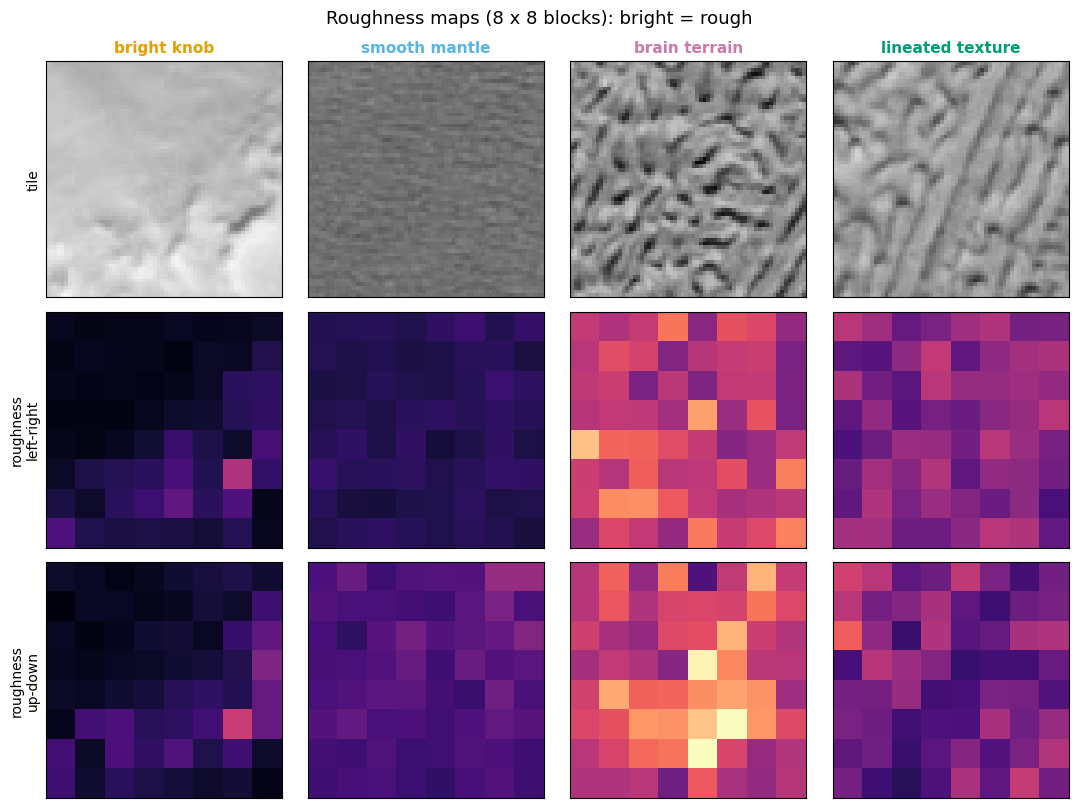

In [8]:
def roughness(x):
    # Average size of pixel-to-pixel brightness changes in each 8x8 block (left-right and up-down)
    dx = (x[..., :, 1:] - x[..., :, :-1]).abs()
    dy = (x[..., 1:, :] - x[..., :-1, :]).abs()
    dx = nn.functional.pad(dx, (0, 1, 0, 0))          # pad back to 64 x 64
    dy = nn.functional.pad(dy, (0, 0, 0, 1))
    return torch.cat([nn.functional.avg_pool2d(dx, 8), nn.functional.avg_pool2d(dy, 8)], dim=1)  # (N, 2, 8, 8)

mse = nn.MSELoss()
def loss_fn(output, target):
    return mse(output, target) + ROUGHNESS_WEIGHT * mse(roughness(output), roughness(target))

# What roughness "sees": the example tiles and their roughness maps
fig, ax = plt.subplots(3, 4, figsize=(11, 8.2))
for j, ((name, rc), col) in enumerate(zip(EXAMPLES.items(), EX_COLORS)):
    x = X_all[tile_index[rc]][None]
    r = roughness(x)[0]
    ax[0, j].imshow(x[0, 0], cmap='gray', vmin=0, vmax=1); ax[0, j].set_title(name, color=col, weight='bold')
    ax[1, j].imshow(r[0], cmap='magma', vmin=0, vmax=0.12)
    ax[2, j].imshow(r[1], cmap='magma', vmin=0, vmax=0.12)
for a in ax.ravel(): a.set_xticks([]); a.set_yticks([])
ax[0, 0].set_ylabel('tile'); ax[1, 0].set_ylabel('roughness\nleft-right'); ax[2, 0].set_ylabel('roughness\nup-down')
fig.suptitle('Roughness maps (8 x 8 blocks): bright = rough', fontsize=13)
plt.tight_layout(); plt.show()

In [9]:
watch = torch.stack([X_all[tile_index[rc]] for rc in EXAMPLES.values()])   # the 4 example tiles

def train_autoencoder(model, epochs):
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    steps_per_epoch = int(np.ceil(len(X_train) / BATCH_SIZE))
    # "One-cycle" schedule: the learning rate warms up, then decays smoothly towards 0
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=LR, total_steps=epochs * steps_per_epoch)
    history = {'loss': [], 'test_loss': [], 'snapshots': []}
    for epoch in range(1, epochs + 1):
        model.train()
        order, running = torch.randperm(len(X_train)), 0.0
        for b in range(0, len(X_train), BATCH_SIZE):
            x = X_train[order[b:b + BATCH_SIZE]]
            x = torch.rot90(x, np.random.randint(4), dims=(2, 3))   # random rotation
            if np.random.rand() < 0.5:
                x = x.flip(3)                                       # random mirror
            x = x.to(device)
            loss = loss_fn(model(x), x)        # 1-2. forward pass and loss (target = input!)
            optimizer.zero_grad()
            loss.backward()                    # 3. gradients
            optimizer.step()                   # 4. update weights
            scheduler.step()
            running += loss.item() * len(x)
        model.eval()
        with torch.no_grad():
            test_loss = loss_fn(model(X_test.to(device)), X_test.to(device)).item()
            history['snapshots'].append(model(watch.to(device)).cpu())
        history['loss'].append(running / len(X_train)); history['test_loss'].append(test_loss)
        if epoch == 1 or epoch % 10 == 0:
            print(f'epoch {epoch:3d}/{epochs} | train loss {history["loss"][-1]:.5f} | test loss {test_loss:.5f}')
    return history

history = train_autoencoder(model, EPOCHS)

epoch   1/80 | train loss 0.02696 | test loss 0.03040
epoch  10/80 | train loss 0.01338 | test loss 0.01251
epoch  20/80 | train loss 0.01186 | test loss 0.01073
epoch  30/80 | train loss 0.01145 | test loss 0.01061
epoch  40/80 | train loss 0.01113 | test loss 0.01048
epoch  50/80 | train loss 0.01106 | test loss 0.01012
epoch  60/80 | train loss 0.01083 | test loss 0.01019
epoch  70/80 | train loss 0.01067 | test loss 0.00992
epoch  80/80 | train loss 0.01058 | test loss 0.00990


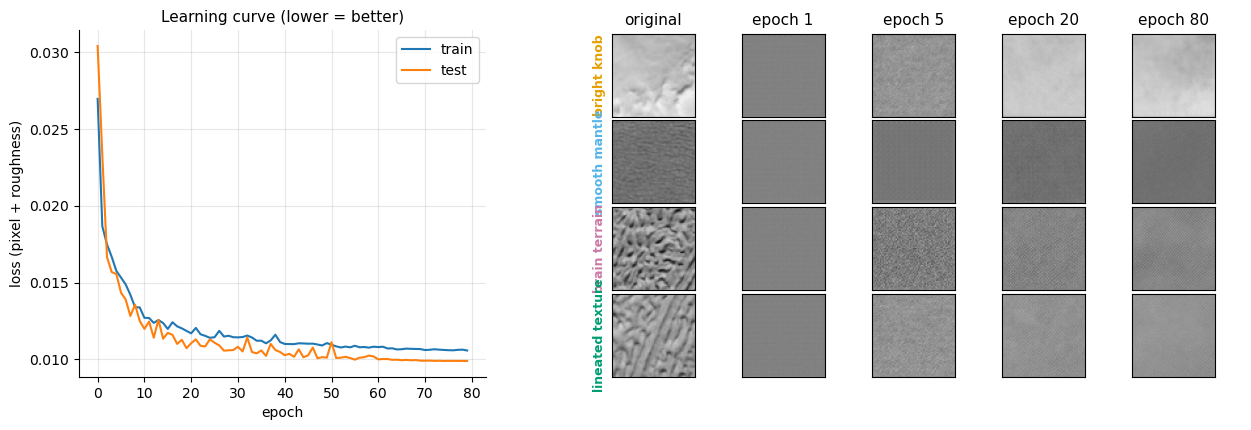

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={'width_ratios': [1, 1.6]})
ax[0].plot(history['loss'], label='train'); ax[0].plot(history['test_loss'], label='test')
ax[0].set_xlabel('epoch'); ax[0].set_ylabel('loss (pixel + roughness)'); ax[0].set_title('Learning curve (lower = better)')
ax[0].legend(); ax[0].grid(alpha=0.3); ax[0].spines[['top', 'right']].set_visible(False)

# Watch the reconstructions sharpen over the epochs
ax[1].axis('off')
show = [1, 5, 20, EPOCHS]
for j, (name, col) in enumerate(zip(EXAMPLES, EX_COLORS)):
    for i, e in enumerate([0] + show):
        a = ax[1].inset_axes([i / 5, 1 - (j + 1) / 4, 0.19, 0.24])
        a.imshow(watch[j, 0] if e == 0 else history['snapshots'][e - 1][j, 0], cmap='gray', vmin=0, vmax=1)
        a.set_xticks([]); a.set_yticks([])
        if j == 0: a.set_title('original' if e == 0 else f'epoch {e}')
        if i == 0: a.set_ylabel(name, color=col, fontsize=9, weight='bold')
plt.show()

---
## Step 4: How good are the reconstructions?

Each reconstruction below was rebuilt from **just 16 numbers**. The *difference* panel shows what was lost (bright = big error).

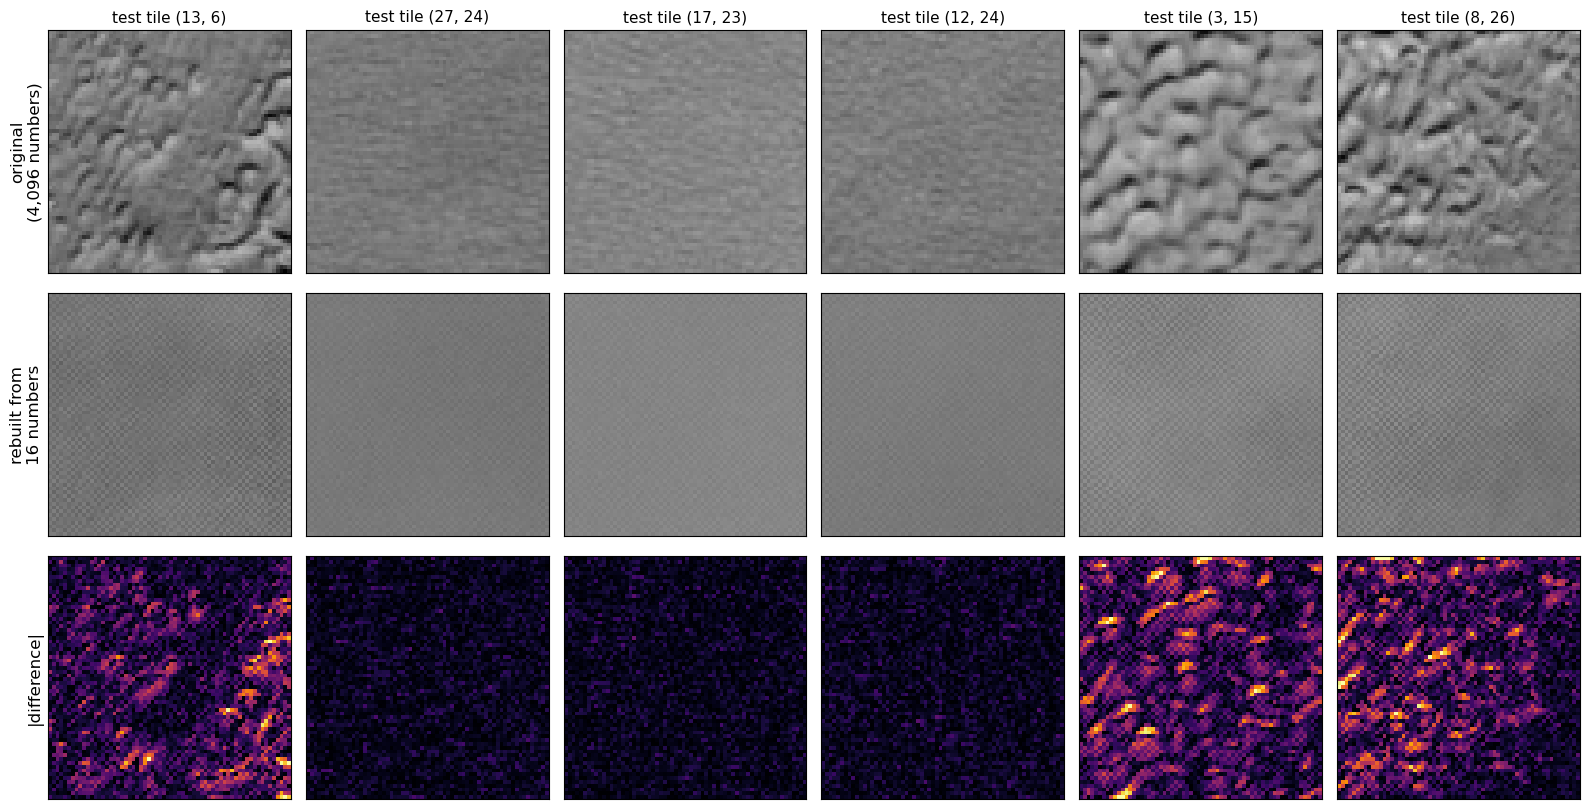

In [11]:
model.eval()
with torch.no_grad():
    Z_all = model.encode(X_all.to(device)).cpu().numpy()              # latent vectors of ALL 840 tiles
    recon_all = model.decode(torch.tensor(Z_all).to(device)).cpu().numpy()[:, 0]

fig, ax = plt.subplots(3, 6, figsize=(16, 8.3))
for j, i in enumerate(test_idx[:6]):
    err = np.abs(tiles[i] - recon_all[i])
    ax[0, j].imshow(tiles[i], cmap='gray', vmin=0, vmax=1)
    ax[1, j].imshow(recon_all[i], cmap='gray', vmin=0, vmax=1)
    ax[2, j].imshow(err, cmap='inferno', vmin=0, vmax=0.4)
    ax[0, j].set_title(f'test tile {rc_text(i)}')
for a in ax.ravel(): a.set_xticks([]); a.set_yticks([])
for a, t in zip(ax[:, 0], ['original\n(4,096 numbers)', 'rebuilt from\n16 numbers', '|difference|']):
    a.set_ylabel(t, fontsize=12)
plt.tight_layout(); plt.show()

Now rebuild the **whole scene**, tile by tile, from 16 numbers per tile:

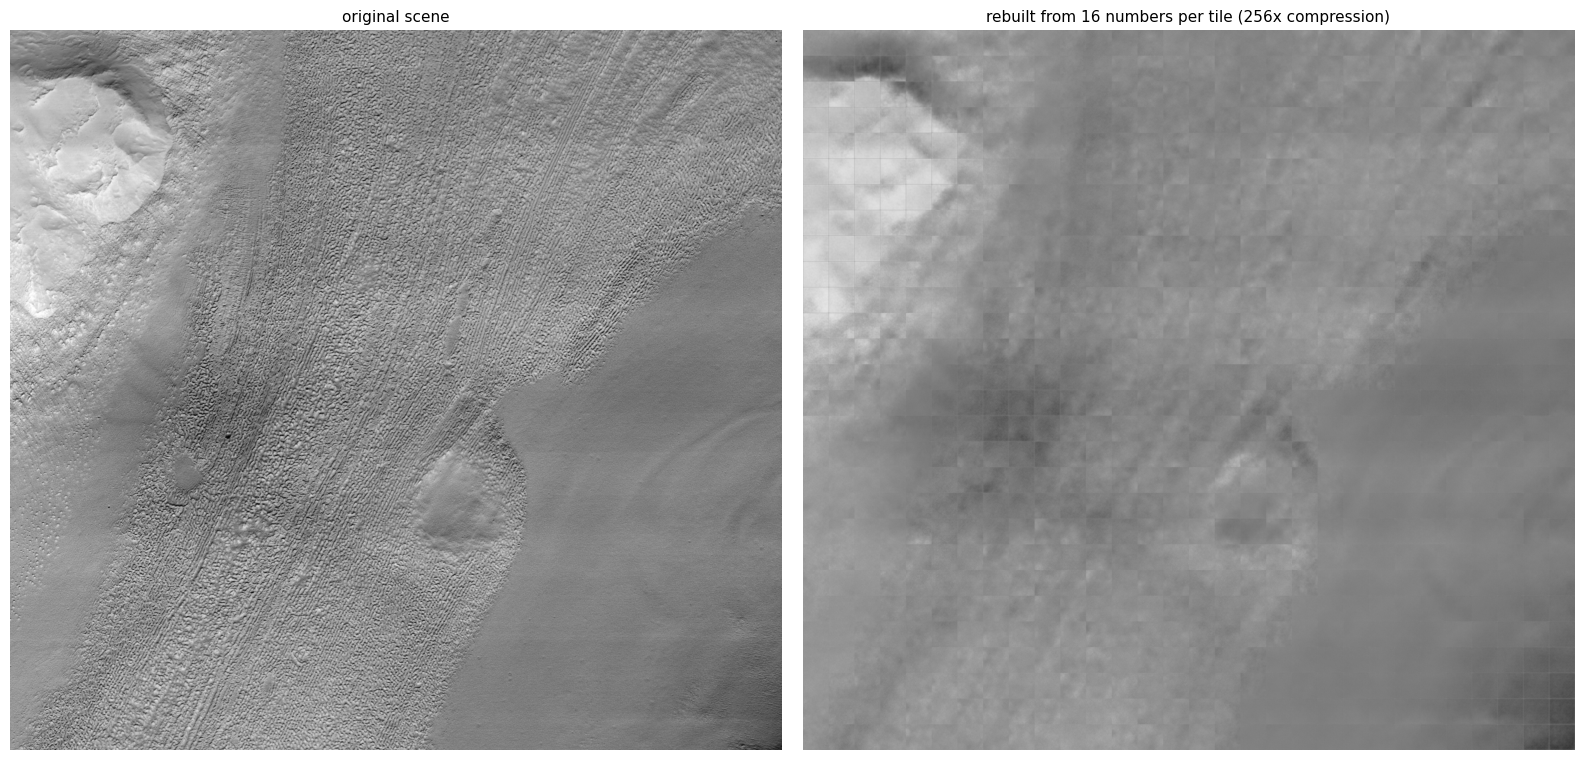

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(16, 7.5))
ax[0].imshow(mosaic, cmap='gray', vmin=0, vmax=1); ax[0].set_title('original scene')
ax[1].imshow(assemble(recon_all), cmap='gray', vmin=0, vmax=1)
ax[1].set_title(f'rebuilt from {LATENT_DIM} numbers per tile ({T * T // LATENT_DIM}x compression)')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

---
## Step 5: Explore the latent space

### 5a. An image as 16 numbers
Every tile is now described by a **latent vector** of 16 numbers. Below are the vectors of our four example tiles, shown as bar charts. The decoder sees *only these bars* and turns them back into an image.

(We **standardize** each of the 16 numbers, subtracting its average over all tiles and dividing by its spread, so that bars above 0 mean "more than a typical tile" and bars below 0 mean "less". The 16 numbers have **no spatial meaning**: number 3 is not "the top-left corner".)

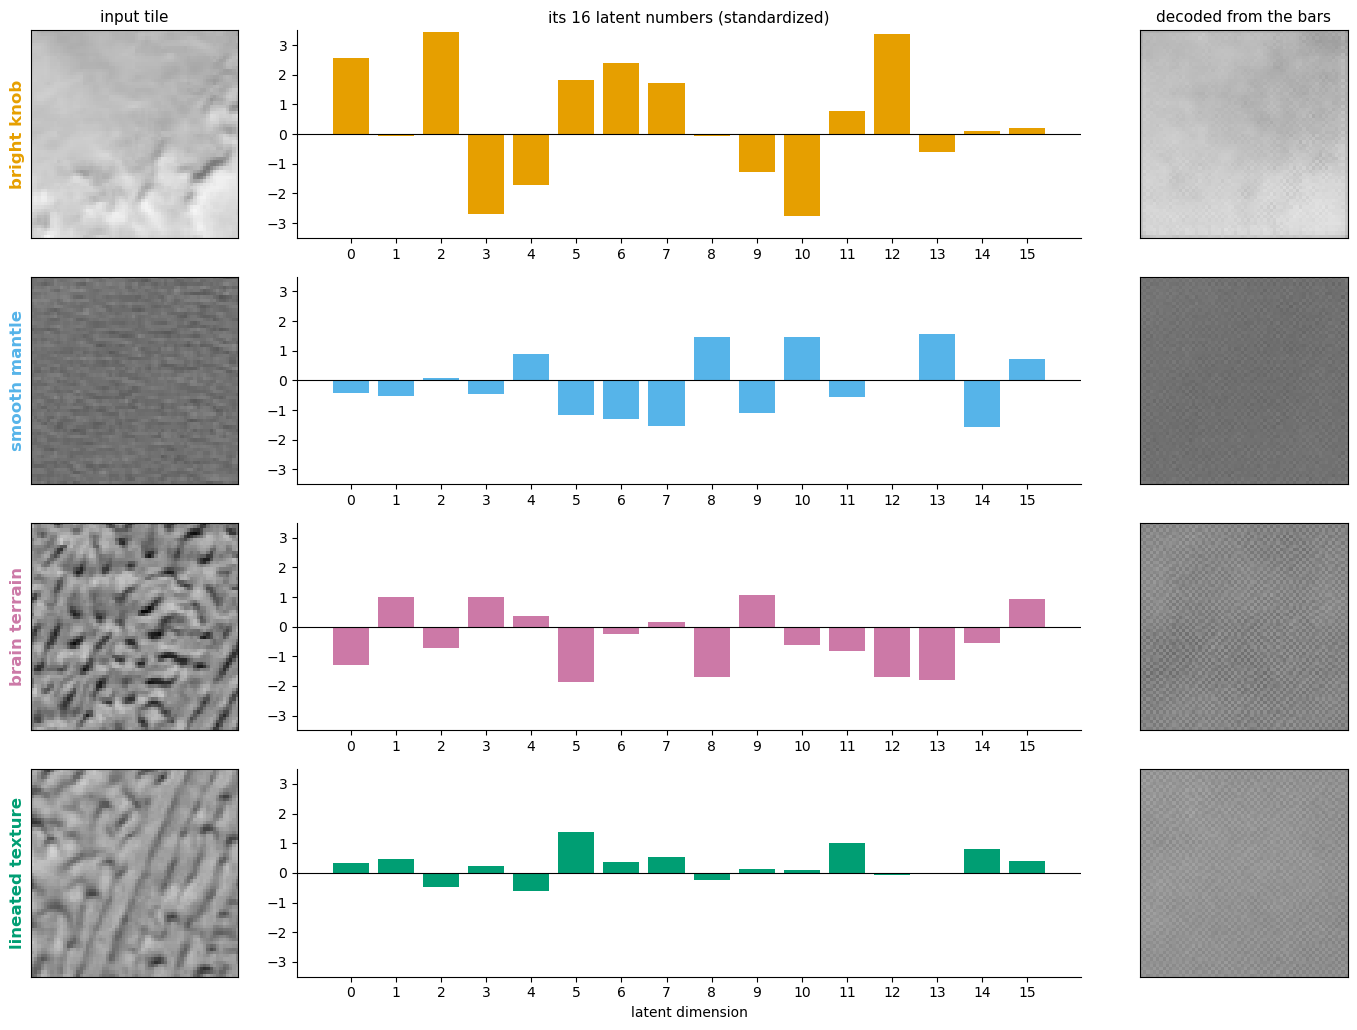

In [13]:
Z_mean, Z_std = Z_all.mean(0), Z_all.std(0)
Zs = (Z_all - Z_mean) / Z_std                  # standardized latent vectors, used from here on

fig, ax = plt.subplots(len(EXAMPLES), 3, figsize=(14, 2.6 * len(EXAMPLES)),
                       gridspec_kw={'width_ratios': [1, 3.2, 1]})
for r, ((name, rc), col) in enumerate(zip(EXAMPLES.items(), EX_COLORS)):
    i = tile_index[rc]
    ax[r, 0].imshow(tiles[i], cmap='gray', vmin=0, vmax=1)
    ax[r, 0].set_ylabel(name, color=col, fontsize=12, weight='bold')
    ax[r, 1].bar(range(LATENT_DIM), Zs[i], color=col)
    ax[r, 1].axhline(0, color='k', lw=0.8); ax[r, 1].set_ylim(-3.5, 3.5)
    ax[r, 1].set_xticks(range(LATENT_DIM)); ax[r, 1].spines[['top', 'right']].set_visible(False)
    ax[r, 2].imshow(recon_all[i], cmap='gray', vmin=0, vmax=1)
    for a in (ax[r, 0], ax[r, 2]): a.set_xticks([]); a.set_yticks([])
ax[0, 0].set_title('input tile'); ax[0, 1].set_title('its 16 latent numbers (standardized)')
ax[0, 2].set_title('decoded from the bars'); ax[-1, 1].set_xlabel('latent dimension')
plt.tight_layout(); plt.show()

### 5b. What do the main directions in latent space mean?
The 16 numbers are correlated with each other, so it is hard to interpret them one at a time. Instead we use **PCA** (principal component analysis) to find the **three directions along which the tiles vary most**.

To see what a direction means, we give every tile a score along it, then line up **real tiles** from the lowest score (left) to the highest (right).

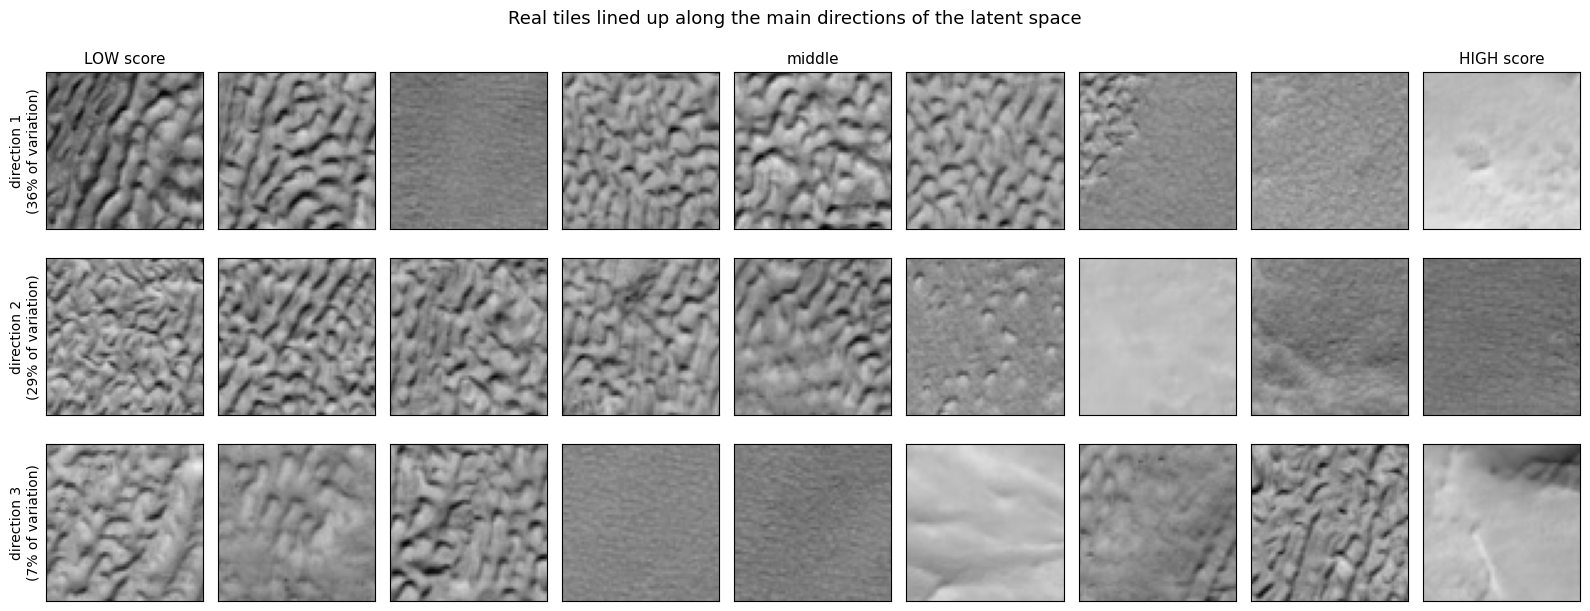

In [14]:
pca = PCA(n_components=3).fit(Zs)
scores = pca.transform(Zs)                      # each tile's position along the 3 main directions
n_show = 9
ranks = np.linspace(0.02, 0.98, n_show)         # skip the most extreme 2% at each end

fig, ax = plt.subplots(3, n_show, figsize=(16, 6.4))
for p in range(3):
    order = np.argsort(scores[:, p])
    for j, q in enumerate(ranks):
        i = order[int(q * (len(order) - 1))]
        ax[p, j].imshow(tiles[i], cmap='gray', vmin=0, vmax=1); ax[p, j].set_xticks([]); ax[p, j].set_yticks([])
    ax[p, 0].set_ylabel(f'direction {p + 1}\n({100 * pca.explained_variance_ratio_[p]:.0f}% of variation)', fontsize=10)
ax[0, 0].set_title('LOW score'); ax[0, n_show // 2].set_title('middle'); ax[0, -1].set_title('HIGH score')
fig.suptitle('Real tiles lined up along the main directions of the latent space', fontsize=13)
plt.tight_layout(); plt.show()

### 5c. Morphing one terrain into another (interpolation)
Because similar tiles have nearby latent vectors, the space between two tiles is filled with *in-between* terrain. Here we walk in a straight line through latent space from the **smooth mantle** tile to the **brain terrain** tile. At each step we show:
* **top row:** what the decoder draws at that point (blurry, because 16 numbers cannot store every ridge);
* **bottom row:** the **real tile** whose latent vector is closest to that point.

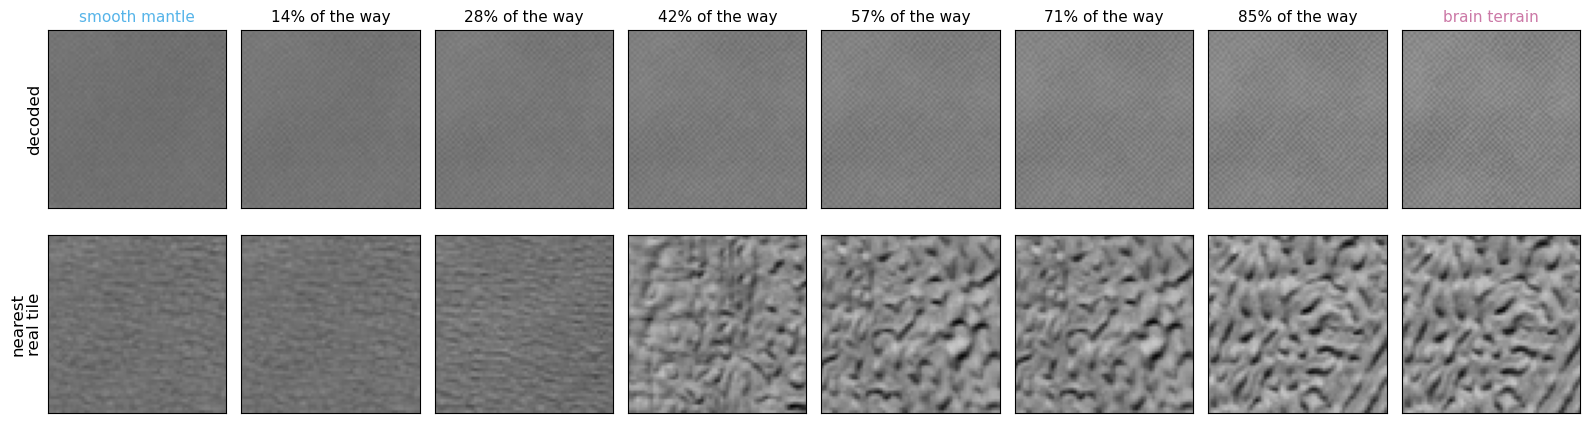

In [15]:
a, b = tile_index[EXAMPLES['smooth mantle']], tile_index[EXAMPLES['brain terrain']]
alphas = np.linspace(0, 1, 8)
z_path = np.array([(1 - t) * Z_all[a] + t * Z_all[b] for t in alphas], dtype=np.float32)
with torch.no_grad():
    morph = model.decode(torch.tensor(z_path).to(device)).cpu().numpy()[:, 0]
nearest = NearestNeighbors(n_neighbors=1).fit(Zs).kneighbors((z_path - Z_mean) / Z_std)[1][:, 0]

fig, ax = plt.subplots(2, len(alphas), figsize=(16, 4.6))
for j, t in enumerate(alphas):
    ax[0, j].imshow(morph[j], cmap='gray', vmin=0, vmax=1)
    ax[1, j].imshow(tiles[nearest[j]], cmap='gray', vmin=0, vmax=1)
    ax[0, j].set_title('smooth mantle' if t == 0 else 'brain terrain' if t == 1 else f'{int(100 * t)}% of the way',
                       color=EX_COLORS[1] if t == 0 else EX_COLORS[2] if t == 1 else 'black')
for x in ax.ravel(): x.set_xticks([]); x.set_yticks([])
ax[0, 0].set_ylabel('decoded', fontsize=12); ax[1, 0].set_ylabel('nearest\nreal tile', fontsize=12)
plt.tight_layout(); plt.show()

---
## Step 6: Similarity search, "find me more tiles like this one"

If the latent space captures what a tile *looks like*, then tiles whose latent vectors are **close together** (small distance between their 16-number vectors) should look alike, even if their pixels don't match one-to-one.

This is how **image retrieval** tools work for large planetary archives (see the [Mars image retrieval demo](https://huggingface.co/spaces/jfang/Mars-ViT-demo), which uses the same idea with a larger network).

Below: a query tile, its 8 nearest neighbors in latent space, and **where those neighbors are in the scene**.

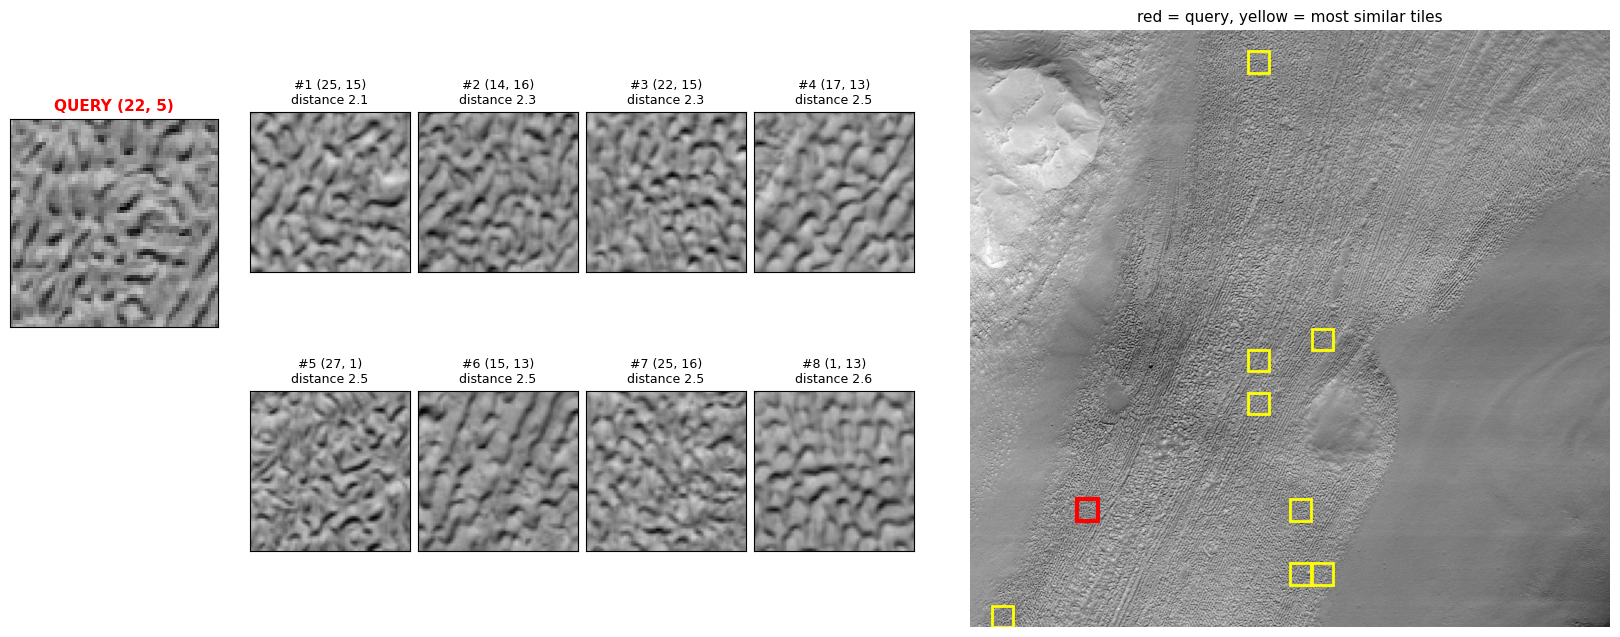

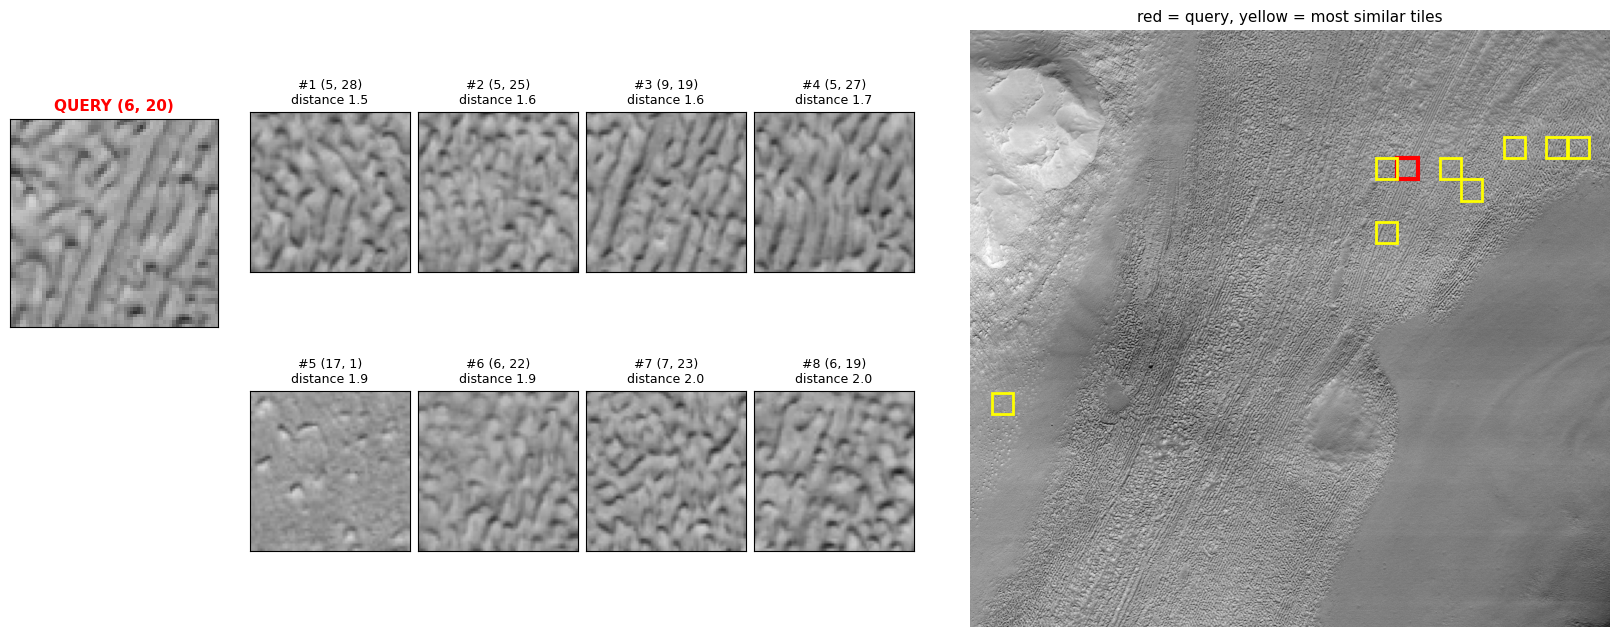

In [16]:
search = NearestNeighbors(n_neighbors=9).fit(Zs)

def find_similar(query_rc, k=8):
    q = tile_index[query_rc]
    dist, nbrs = search.kneighbors(Zs[q:q + 1], n_neighbors=k + 1)
    nbrs, dist = nbrs[0][1:], dist[0][1:]                       # drop the query itself

    fig = plt.figure(figsize=(16, 6.2))
    a = fig.add_axes([0.0, 0.42, 0.13, 0.5]); a.imshow(tiles[q], cmap='gray', vmin=0, vmax=1)
    a.set_title(f'QUERY {query_rc}', color='red', weight='bold'); a.set_xticks([]); a.set_yticks([])
    for j, (n, d) in enumerate(zip(nbrs, dist)):
        a = fig.add_axes([0.15 + 0.105 * (j % 4), 0.52 - 0.45 * (j // 4), 0.1, 0.4])
        a.imshow(tiles[n], cmap='gray', vmin=0, vmax=1); a.set_xticks([]); a.set_yticks([])
        a.set_title(f'#{j + 1} {rc_text(n)}\ndistance {d:.1f}', fontsize=9)
    a = fig.add_axes([0.6, 0.0, 0.4, 1.0]); a.imshow(mosaic, cmap='gray'); a.axis('off')
    mark_tile(a, query_rc, 'red', lw=3)
    for n in nbrs:
        mark_tile(a, tuple(grid_pos[n]), 'yellow', lw=2)
    a.set_title('red = query, yellow = most similar tiles')
    plt.show()

# 🔧 Try it: any (row, col) with row 0-27 and col 0-29, e.g. one of the EXAMPLES
find_similar(EXAMPLES['brain terrain'])
find_similar(EXAMPLES['lineated texture'])

---
## Step 7: Cluster the latent space and make a terrain map

### 7a. A 2-D map of the latent space
We can't picture 16 dimensions, so we use **t-SNE**, a method that squashes the 840 latent vectors onto a 2-D sheet while trying to keep **neighbors next to neighbors**. Then we place real tile thumbnails on that sheet (one per grid cell, so they don't overlap).

Caution: t-SNE is only for **looking**. Distances between far-apart groups and the size of groups on a t-SNE plot are not meaningful.

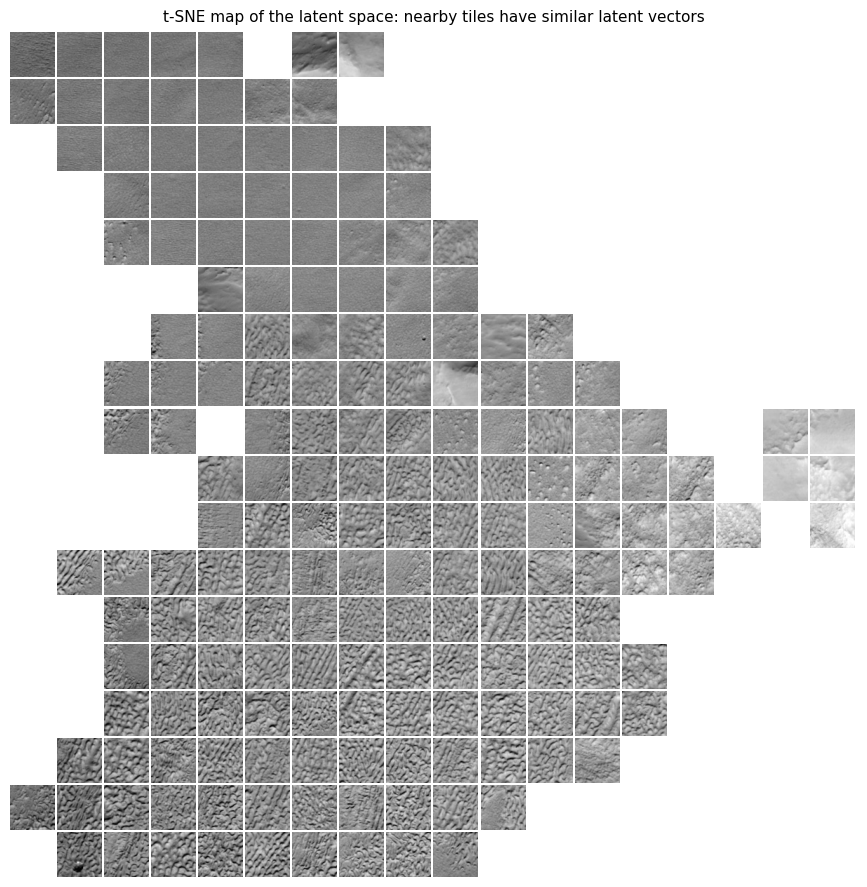

In [17]:
xy = TSNE(n_components=2, perplexity=30, random_state=SEED).fit_transform(Zs)

def thumbnail_map(xy, n_cells=18, ax=None, title=''):
    # Show one representative tile per occupied cell of an n_cells x n_cells grid over the 2-D map
    ax = ax or plt.gca()
    lo, hi = xy.min(0), xy.max(0)
    cell = np.floor((xy - lo) / (hi - lo + 1e-9) * n_cells).astype(int)
    for cx in range(n_cells):
        for cy in range(n_cells):
            members = np.where((cell[:, 0] == cx) & (cell[:, 1] == cy))[0]
            if len(members):
                centre = (np.array([cx, cy]) + 0.5) / n_cells * (hi - lo) + lo
                pick = members[np.argmin(((xy[members] - centre) ** 2).sum(1))]
                ax.imshow(tiles[pick], cmap='gray', vmin=0, vmax=1,
                          extent=[cx, cx + 0.95, cy, cy + 0.95])
    ax.set_xlim(0, n_cells); ax.set_ylim(0, n_cells); ax.set_aspect('equal'); ax.axis('off'); ax.set_title(title)

plt.figure(figsize=(11, 11))
thumbnail_map(xy, title='t-SNE map of the latent space: nearby tiles have similar latent vectors')
plt.show()

### 7b. Group the tiles with k-means
**k-means** splits the tiles into `N_CLUSTERS` groups so that tiles in a group have similar latent vectors. We cluster on the **16 latent numbers**, not on the t-SNE picture. The number of groups is our choice (🔧 change `N_CLUSTERS` in the settings).

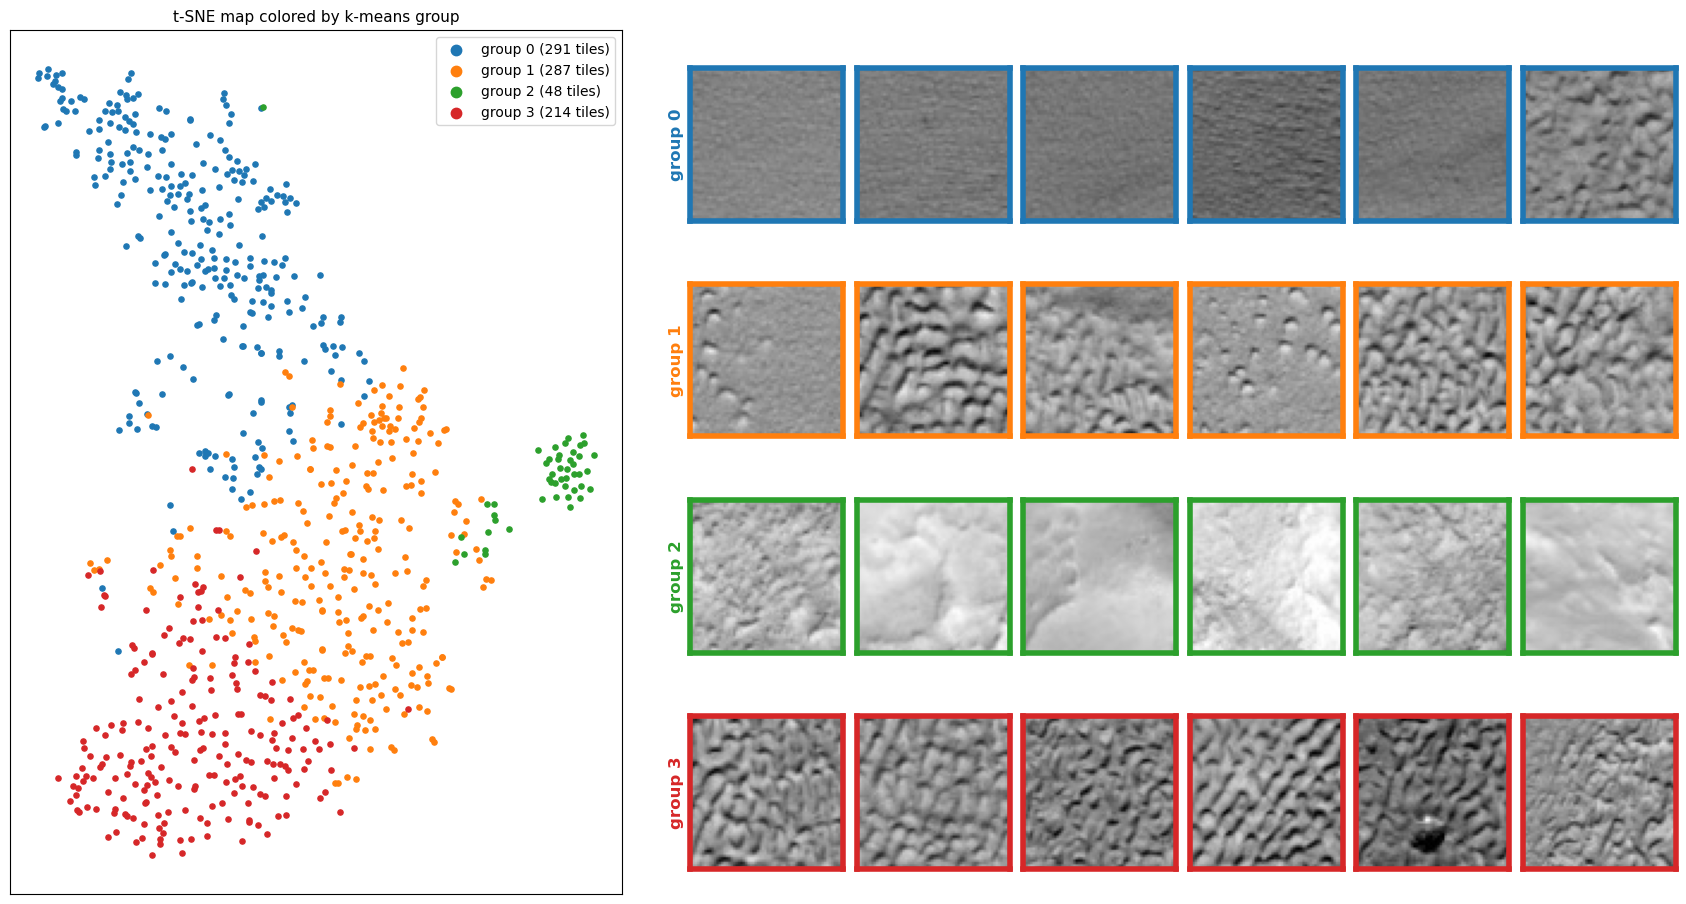

In [18]:
labels = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=SEED).fit_predict(Zs)
CL_COLORS = plt.cm.tab10(np.arange(N_CLUSTERS))

fig = plt.figure(figsize=(17, 2.4 * N_CLUSTERS))
a = fig.add_axes([0.0, 0.05, 0.36, 0.9])
for k in range(N_CLUSTERS):
    m = labels == k
    a.scatter(xy[m, 0], xy[m, 1], s=14, color=CL_COLORS[k], label=f'group {k} ({m.sum()} tiles)')
a.legend(markerscale=2); a.set_title('t-SNE map colored by k-means group'); a.set_xticks([]); a.set_yticks([])

rng = np.random.default_rng(SEED)
for k in range(N_CLUSTERS):
    members = np.where(labels == k)[0]
    for j, i in enumerate(rng.choice(members, min(6, len(members)), replace=False)):
        b = fig.add_axes([0.4 + 0.098 * j, 0.95 - (k + 1) * 0.9 / N_CLUSTERS, 0.09, 0.85 / N_CLUSTERS])
        b.imshow(tiles[i], cmap='gray', vmin=0, vmax=1); b.set_xticks([]); b.set_yticks([])
        for s in b.spines.values(): s.set_color(CL_COLORS[k]); s.set_linewidth(4)
        if j == 0: b.set_ylabel(f'group {k}', color=CL_COLORS[k], fontsize=12, weight='bold')
plt.show()

### 7c. Put the groups back on the map
Each tile knows its (row, column) in the scene, so we can paint every tile with its group color. The result is an **unsupervised terrain map**: no one told the network what any terrain was.

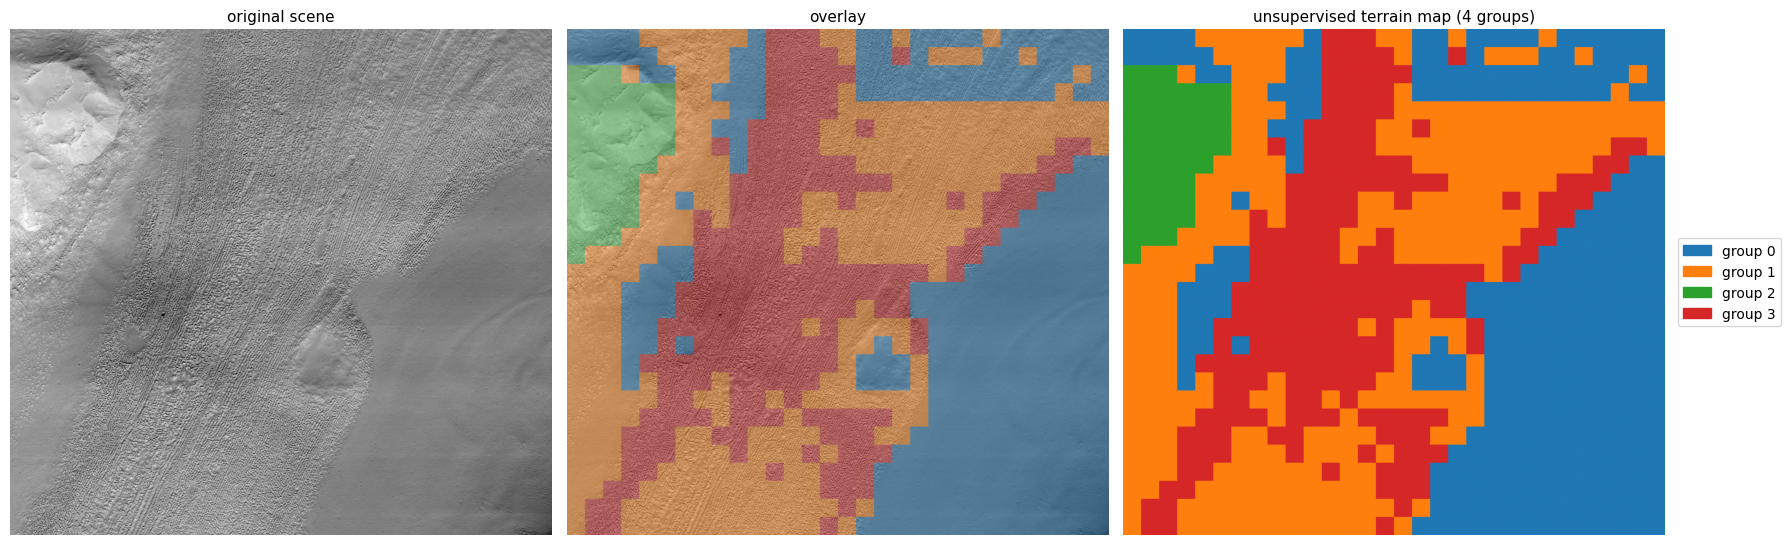

In [19]:
group_grid = np.zeros((ROWS, COLS), int)
group_grid[grid_pos[:, 0], grid_pos[:, 1]] = labels
group_rgb = np.kron(CL_COLORS[group_grid][..., :3], np.ones((T, T, 1)))     # one color block per tile
scene_rgb = np.repeat(mosaic[..., None], 3, axis=2)

fig, ax = plt.subplots(1, 3, figsize=(18, 6.5))
ax[0].imshow(mosaic, cmap='gray'); ax[0].set_title('original scene')
ax[1].imshow(np.clip(0.55 * scene_rgb + 0.45 * group_rgb, 0, 1)); ax[1].set_title('overlay')
ax[2].imshow(group_rgb); ax[2].set_title(f'unsupervised terrain map ({N_CLUSTERS} groups)')
for a in ax: a.axis('off')
ax[2].legend(handles=[Patch(color=CL_COLORS[k], label=f'group {k}') for k in range(N_CLUSTERS)],
             loc='center left', bbox_to_anchor=(1.01, 0.5))
plt.tight_layout(); plt.show()

---
## Exercises
0. **What does the roughness term buy us?** Set `ROUGHNESS_WEIGHT = 0` (plain pixel loss) and re-run the notebook. Compare the similarity search in Step 6 and the map in Step 7c with your current results. What does the latent space capture now, and why? *(This is the most important exercise.)*
1. **Bottleneck size.** Re-run with `LATENT_DIM = 2, 4, 64`. Plot test loss vs. latent size. When do reconstructions become "good enough"? Does the terrain map get better or worse?
2. **Number of groups.** Try `N_CLUSTERS = 3, 5, 6`. Which value gives the most geologically meaningful map? Is there a "right" answer?
3. **Brightness vs. texture.** Normalize each tile to zero mean and unit spread before training (so only texture remains). How do the groups and the map change?
4. **Pixels vs. latent space.** Run k-means directly on the raw pixels (`tiles.reshape(840, -1)`) instead of `Zs`. Compare the maps. What does the autoencoder add?
5. **Similarity search.** Pick three query tiles from different units. For which unit does the search work best, and why?

## Going further: Variational Autoencoders (VAEs)
A VAE is an autoencoder whose latent space is forced to be smooth and well-organized (each tile maps to a small cloud of points, not a single point). This makes interpolation and generation of new images more reliable, and it is widely used in planetary and spectral data analysis.
* [An Introduction to Variational Autoencoders](https://arxiv.org/abs/1906.02691) (Kingma & Welling, 2019)
* [Convolutional VAE tutorial (TensorFlow)](https://www.tensorflow.org/tutorials/generative/cvae)
* [VAE application to CRISM spectral data](https://www.hou.usra.edu/meetings/tenthmars2024/pdf/3166.pdf) (Tenth Mars conference, 2024)
* [DIVA: Domain Invariant Variational Autoencoders](https://arxiv.org/abs/1905.10427)

## Summary
* An **autoencoder** learns without labels by compressing and rebuilding its input.
* The small **bottleneck** forces it to keep the most important patterns: brightness, roughness, and texture orientation, not individual pixels.
* The resulting **latent space** puts similar terrain close together, which enables **similarity search**, **clustering**, and **unsupervised mapping**.
* Its notion of "similar" or "strange" is limited to what it learned to reconstruct, so always check the results with geologic judgment.

## Applications in planetary science
1. Hayat, Y., & Rubanenko, L. (2026). Automatic classification of planetary surfaces using autoencoders with applications to dunes in the north polar erg of Mars. *Journal of Geophysical Research: Machine Learning and Computation*, 3(3), e2025JH000997. [doi:10.1029/2025JH000997](https://agupubs.onlinelibrary.wiley.com/doi/full/10.1029/2025JH000997)
2. A. Lesnikowski, V. T. Bickel and D. Angerhausen, (2024). Automated Discovery of Anomalous Features in Ultralarge Planetary Remote-Sensing Datasets Using Variational Autoencoders.  *IEEE Journal of Selected Topics in Applied Earth Observations and Remote Sensing*, vol. 17, pp. 6589-6600,  [doi: 10.1109/JSTARS.2024.3369101](https://ieeexplore.ieee.org/document/10444013)
